# ShelfSight: Apparel Catalog Classification

An executed evidence notebook for a reproducible retail portfolio project. It reads committed benchmark artifacts; training and inference are available through the packaged CLI. No data download or training occurs here.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "reports").exists():
    ROOT = ROOT.parent
REPORT = ROOT / "reports"
audit = json.loads((REPORT / "data_audit.json").read_text())
display(pd.Series(audit, name="Data audit").to_frame())

,Data audit
official_train_rows,60000
official_test_rows,10000
exact_test_matches_excluded,10
development_duplicate_images,43
eligible_development_rows,59947
train_rows,12000
validation_rows,3000
test_rows,10000
normalization_mean,0.284331
normalization_std,0.351517


## Evaluation partitions

Partition sizes and isolation are audited below. Validation selects the model; held-out observations are used for the final metrics.

In [2]:
manifest = pd.read_csv(REPORT / "split_manifest.csv")
display(manifest.groupby("split").size().rename("observations").to_frame())
GROUP = "Clothing ID" if "Clothing ID" in manifest else "pixel_sha256"
assert manifest.groupby(GROUP).split.nunique().max() == 1
print("No group crosses partitions")

,observations
split,
test,10000
train,12000
validation,3000


No group crosses partitions


## Controlled experiments

Configurations use bounded training budgets. Small differences from one seed are not evidence of a universal architecture ranking.

In [3]:
validation = pd.read_csv(REPORT / "validation_experiments.csv")
display(validation.round(4))
display(Markdown((REPORT / "experiment_findings.md").read_text()))

,id,accuracy,macro_f1,log_loss,ece_10_bins,training_seconds,parameters,best_epoch,epochs_run
0,cnn_baseline,0.8083,0.8046,0.5213,0.0352,21.4174,60874,8,8
1,cnn_kernel5,0.8383,0.8347,0.4375,0.0236,35.8469,102090,8,8
2,cnn_stride2,0.8523,0.8512,0.4202,0.0153,11.5876,60874,8,8
3,cnn_more_filters,0.8437,0.8418,0.4318,0.0210,34.8826,167114,7,8
4,cnn_average_pool,0.7817,0.7734,0.5729,0.0344,18.3941,60874,8,8
5,cnn_pool3,0.8550,0.8534,0.4086,0.0093,12.8283,60874,8,8
6,cnn_shallow,0.7863,0.7825,0.5557,0.0221,13.9046,23946,8,8
7,cnn_deep,0.8250,0.8181,0.4934,0.0109,26.7294,97802,7,8
8,cnn_augmentation,0.7660,0.7578,0.5906,0.0317,21.3554,60874,8,8


# Experiment findings

## CNN design under a fixed budget

All nine comparisons use the same 12,000 training images, 3,000 validation images, optimizer and eight-epoch budget. Values below are validation results; the test set does not choose the design.

| Configuration | Macro F1 | Parameters | CPU training seconds | Interpretation |
|---|---:|---:|---:|---|
| Base: three convolutions, max pool 2 | 0.8046 | 60,874 | 21.4 | Reference capacity and spatial resolution |
| Kernel 5 | 0.8347 | 102,090 | 35.8 | Larger receptive fields improve quality here at greater cost |
| Initial stride 2 | 0.8512 | 60,874 | 11.6 | Earlier spatial reduction is effective within this budget |
| More filters | 0.8418 | 167,114 | 34.9 | Added capacity helps over base but does not win |
| Average pooling | 0.7734 | 60,874 | 18.4 | Smoothing loses useful local category evidence in this run |
| Pooling window 3 | **0.8534** | 60,874 | 12.8 | Validation winner; favorable bounded capacity/compute tradeoff |
| Two convolutions | 0.7825 | 23,946 | 13.9 | Smaller representation underperforms the base |
| Four convolutions | 0.8181 | 97,802 | 26.7 | More depth costs more without matching the best pooling design |
| Base plus augmentation | 0.7578 | 60,874 | 21.4 | This recipe/budget underperforms, not evidence against augmentation generally |

Changes in depth/stride/pooling alter effective capacity and spatial information; single-seed observations cannot establish the mechanism causally. Parameters describe model capacity, while online training loss and validation loss reflect different dropout/augmentation conditions. Most runs reached the budget limit, so the table does not establish converged performance.

## Transfer and held-out performance

Frozen MobileNetV3-Small features plus a trained linear head achieve validation macro F1 **0.8938** and test macro F1 **0.8983**, above the selected custom CNN's **0.8541**. The custom CNN has **85.62%** held-out accuracy and a pixel-cluster bootstrap macro-F1 interval of approximately **[0.848, 0.860]**. Transfer achieves **89.83%** accuracy and interval **[0.893, 0.904]**. Intervals reflect test sampling, not model-selection uncertainty or seed variability.

MobileNet uses natural-image pretraining, official ImageNet preprocessing and replicated grayscale inputs. Its measured 402-second transfer runtime includes feature extraction for all 25,000 images plus head fitting. The custom winner's 12.8 seconds includes eight training/validation epochs only. This difference is not a direct training-speed comparison.

## Operational failure modes

The selected CNN's Shirt recall is **54.2%**, while Trouser recall is **98.0%**. Overall accuracy conceals difficulty distinguishing shirts, pullovers, coats and tops. The confidence gallery shows wrong classifications even with near-one softmax confidence. The selected CNN's aggregate ten-bin ECE is 0.0074; this aggregate calibration statistic does not make every individual prediction trustworthy.

The bounded linear-pixel reference achieves 82.59% accuracy but substantially worse probability log loss (3.052) and ECE (0.129). It reached its iteration limit, so it should not be described as an optimized or calibrated baseline. Accuracy alone is insufficient when model confidence determines automation.

The fixed augmentation recipe reduces test macro F1 from 0.8044 to 0.7623 at the same epoch budget. Small rotations/crops can remove fine shape evidence from these thumbnails; augmented training may also need more epochs. Further experiments should distinguish these explanations rather than claim a universal effect.

The packaged inference command deliberately exposes the selected custom CNN as a local benchmark prototype. Transfer is an evaluated reference, not a separately served model. Real catalog deployment needs representative product photography and taxonomy validation; thumbnail benchmark scores do not establish commercial performance.


## Held-out evidence

Inspect predictive quality together with class imbalance, confidence and operating thresholds.

In [4]:
scores = pd.read_csv(REPORT / "test_metrics.csv")
display(scores.round(4))
predictions = pd.read_csv(REPORT / "test_predictions.csv")
print(f"Saved {len(predictions):,} auditable predictions")

,id,accuracy,macro_f1,log_loss,ece_10_bins,ci_low,ci_high,training_seconds
0,cnn_pool3,0.8562,0.8541,0.3905,0.0074,0.8478,0.8604,12.8283
1,cnn_baseline,0.8088,0.8044,0.4944,0.0311,0.7976,0.8120,21.4174
2,cnn_augmentation,0.7720,0.7623,0.5666,0.0252,0.7550,0.7698,21.3554
3,prior,0.1000,0.0182,2.3026,0.0001,0.0172,0.0191,0.0005
4,linear_pixels,0.8259,0.8239,3.0520,0.1287,0.8169,0.8309,10.2931
5,mobilenet_frozen,0.8983,0.8983,0.3117,0.0271,0.8928,0.9042,401.6493


Saved 60,000 auditable predictions


## Apparel errors and confidence

Similar garment silhouettes are difficult at 28-by-28 resolution. A high model confidence can still accompany a wrong class.

,Unnamed: 0,precision,recall,f1-score,support
0,T-shirt/top,0.7550,0.8320,0.7916,1000.0000
1,Trouser,0.9387,0.9800,0.9589,1000.0000
2,Pullover,0.7866,0.7410,0.7631,1000.0000
3,Dress,0.8838,0.8670,0.8753,1000.0000
4,Coat,0.7560,0.8150,0.7844,1000.0000
5,Sandal,0.9601,0.9380,0.9489,1000.0000
6,Shirt,0.6491,0.5420,0.5907,1000.0000
7,Sneaker,0.8943,0.9480,0.9204,1000.0000
8,Bag,0.9602,0.9640,0.9621,1000.0000
9,Ankle boot,0.9570,0.9350,0.9459,1000.0000


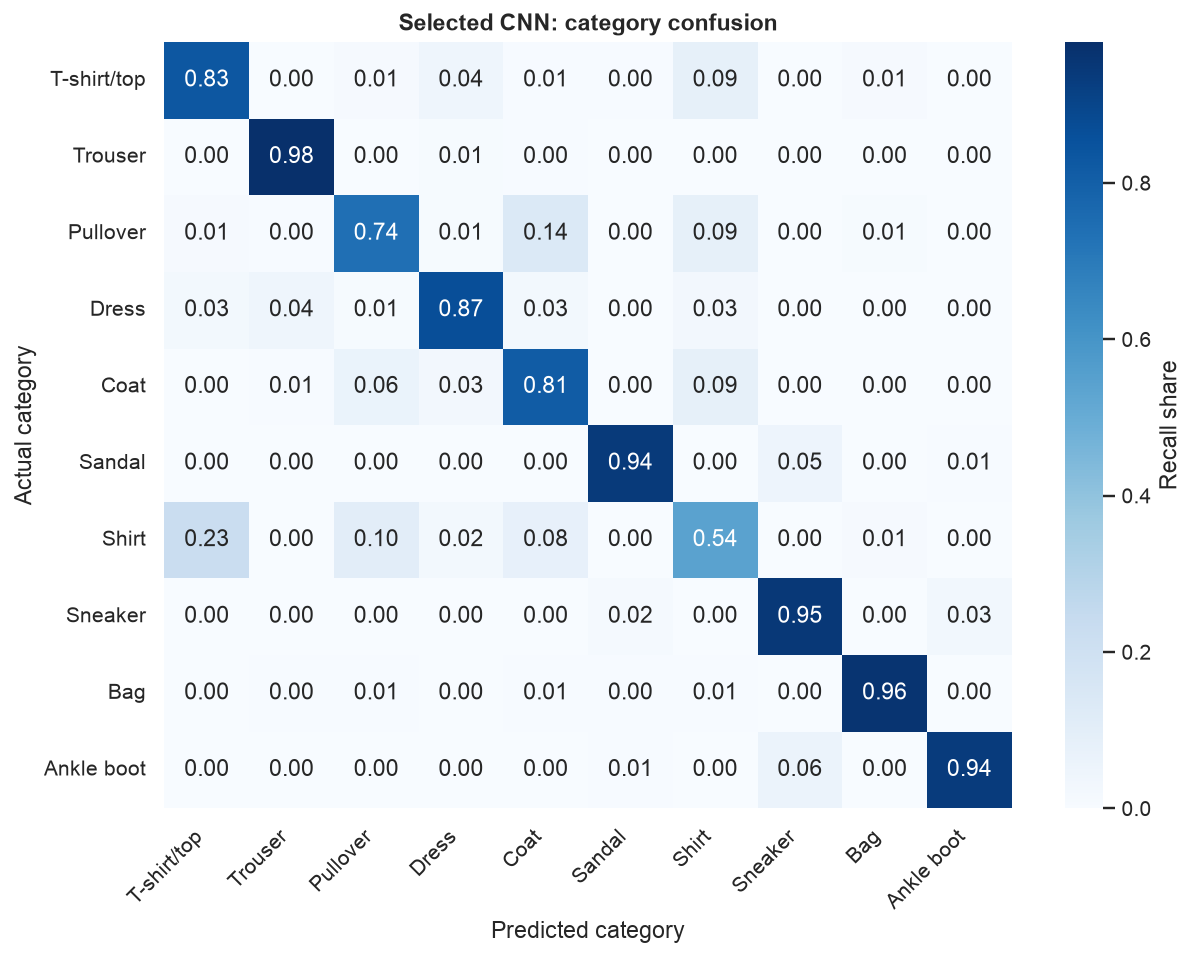

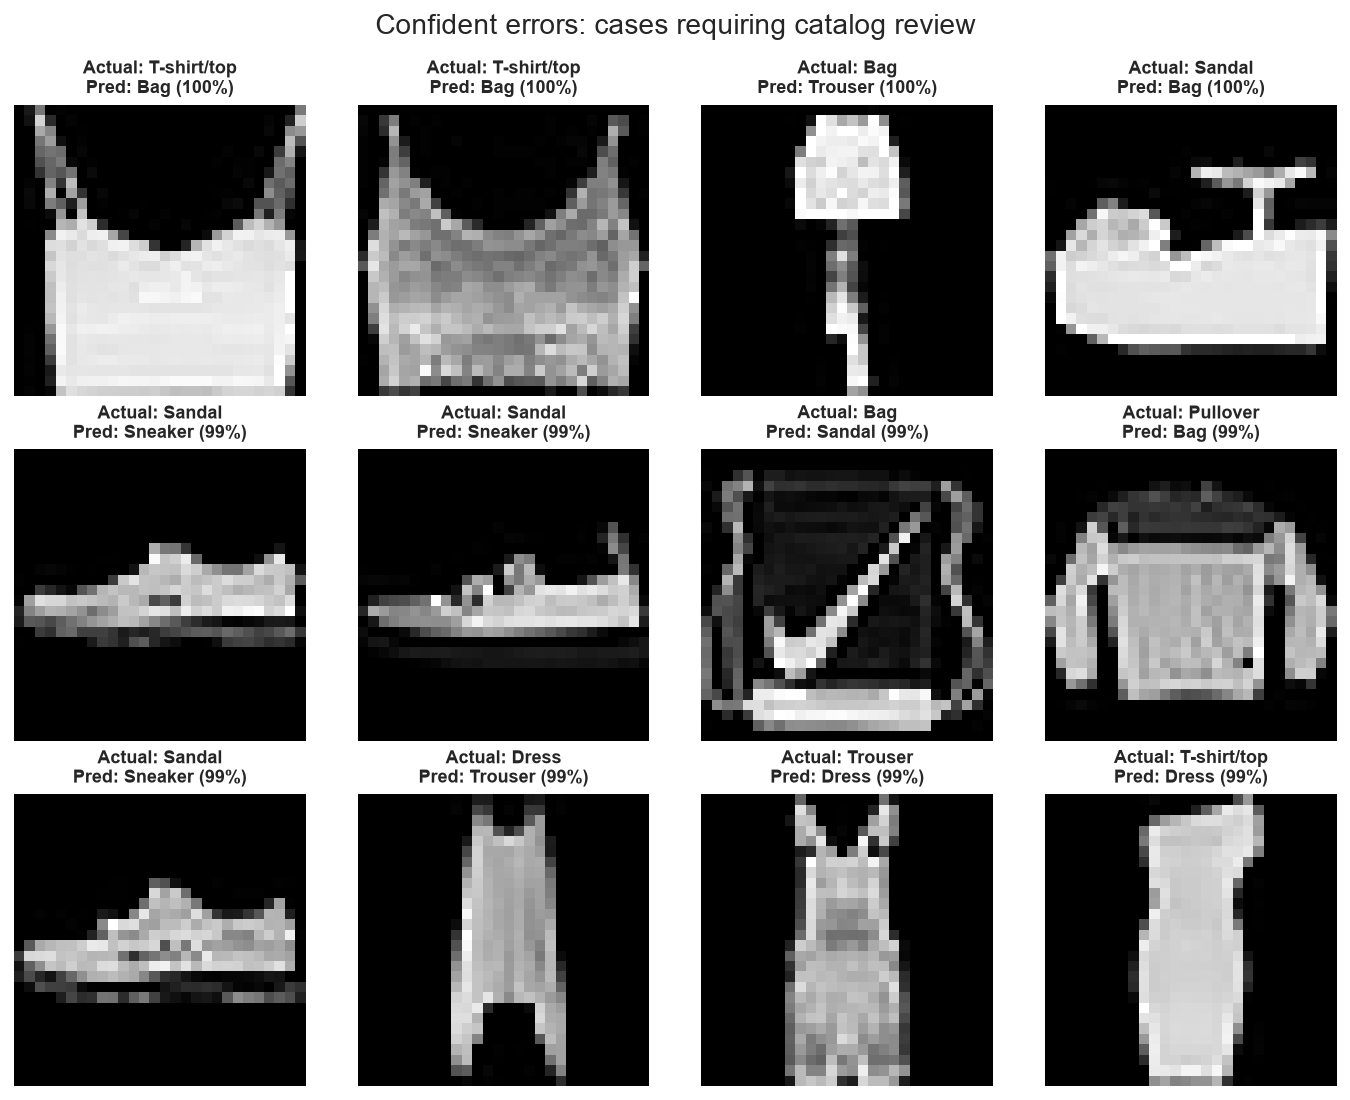

In [5]:
display(pd.read_csv(REPORT / "category_metrics.csv").round(4))
display(Image(filename=str(REPORT / "figures/category_confusion.png")))
display(Image(filename=str(REPORT / "figures/confident_errors.png")))

## Transfer and augmentation

The transfer baseline freezes every pretrained feature layer and fits only a linear head. Its timing includes image feature extraction and is not directly comparable with CNN training time.

,Transfer contract
backbone,MobileNetV3-Small
weights,IMAGENET1K_V1
weights_url,https://download.pytorch.org/models/mobilenet_...
frozen_layers,All pretrained features and pooling; original ...
feature_dimensions,576
head,Train-only StandardScaler + multinomial Logist...
preprocessing,Official resize256/center-crop224/ImageNet nor...
validation,"{'accuracy': 0.8936666666666667, 'macro_f1': 0..."
feature_extraction_seconds,401.128234
head_training_seconds,0.52106


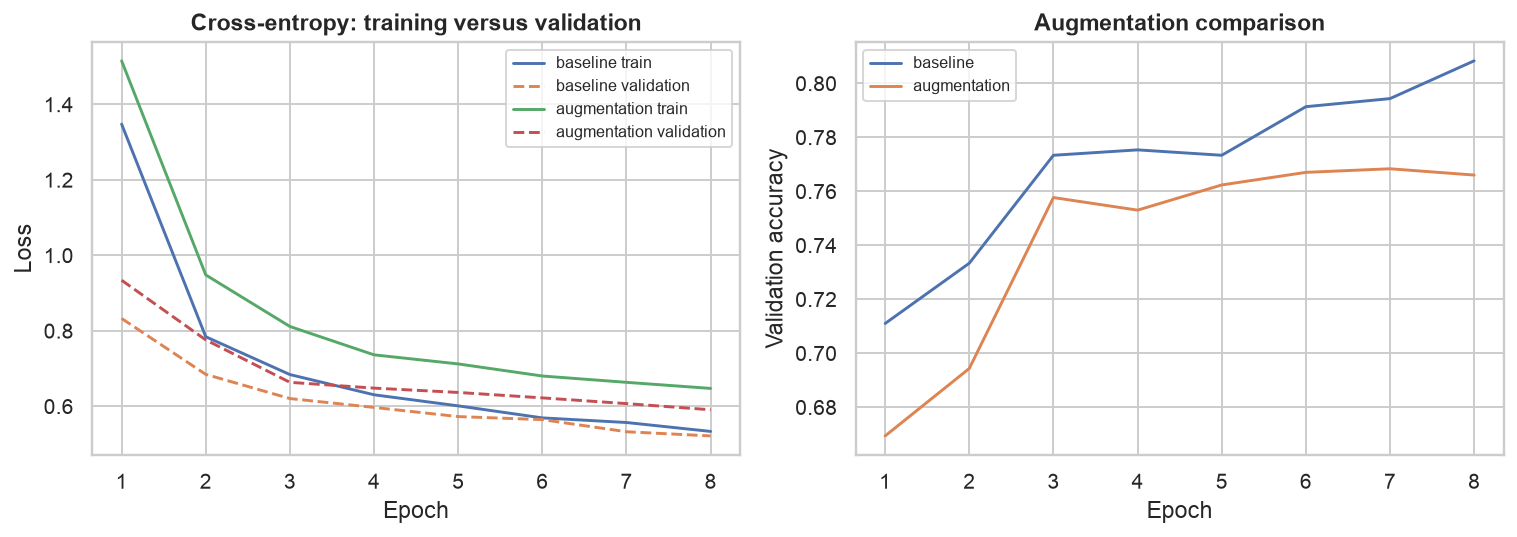

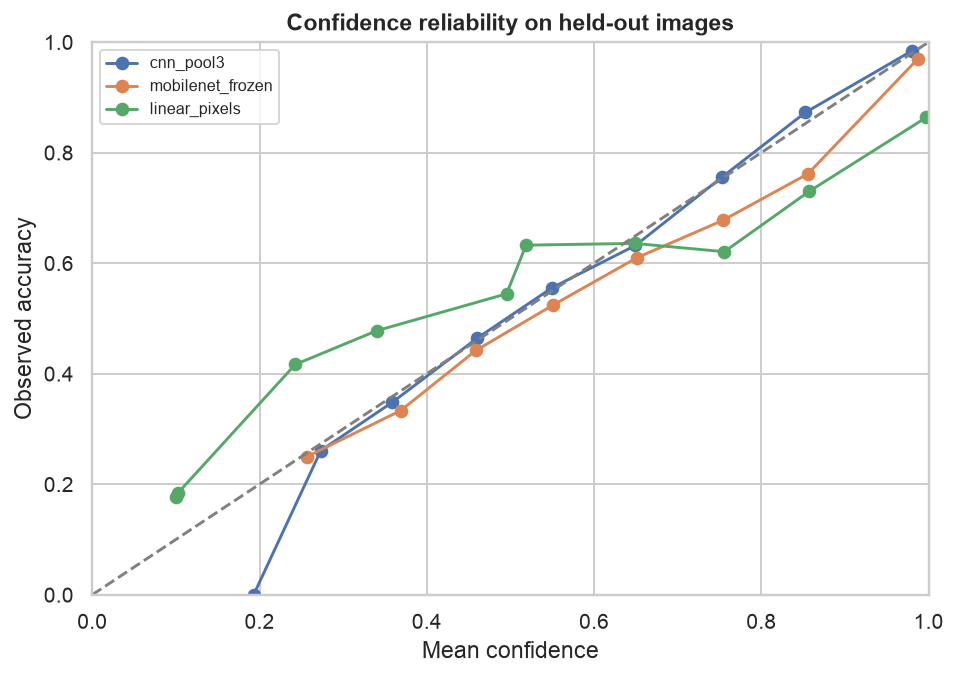

In [6]:
display(
    pd.Series(
        json.loads((REPORT / "transfer_metadata.json").read_text()),
        name="Transfer contract",
    ).to_frame()
)
display(Image(filename=str(REPORT / "figures/training_curves.png")))
display(Image(filename=str(REPORT / "figures/confidence_reliability.png")))

## Inference contract

The example uses a training-pool image with known Pullover label. The selected CNN predicts Coat in this example, illustrating why a category suggestion needs review; this example is not part of held-out scoring.

In [7]:
display(Image(filename=str(ROOT / "data/example_apparel.png"), width=140))
display(
    pd.Series(
        json.loads((REPORT / "example_prediction.json").read_text()), name="Prediction"
    ).to_frame()
)

,Prediction
model,cnn_pool3
predicted_category,Coat
confidence,0.741058
probabilities,"{'T-shirt/top': 0.005273118615150452, 'Trouser..."


## Reproduction and scope

Run the packaged training command to regenerate results and `python scripts/validate_results.py` to independently audit the saved evidence. Model behavior on current retailer data is unmeasured. These results establish an offline benchmark, not a commercial deployment or financial outcome.